# 🏢 Building Segmentation for Thermal Images - Improved Version

**Better detection of Windows, Walls, and Roofs**

Key improvements:
- Multi-scale window detection
- Color-based segmentation (thermal colormap aware)
- Line detection for wall boundaries
- Morphological refinement

## 1. Setup

In [1]:
!pip install -q scikit-image

import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from skimage import segmentation, filters, morphology, measure
from skimage.segmentation import slic, felzenszwalb
from skimage.color import rgb2hsv, rgb2lab
from scipy import ndimage
import warnings
warnings.filterwarnings('ignore')

print("✅ Setup complete!")

✅ Setup complete!


## 2. Upload Image

📤 Upload your thermal image:


Saving IRX_2917.JPG to IRX_2917.JPG

📐 Image: 640x512


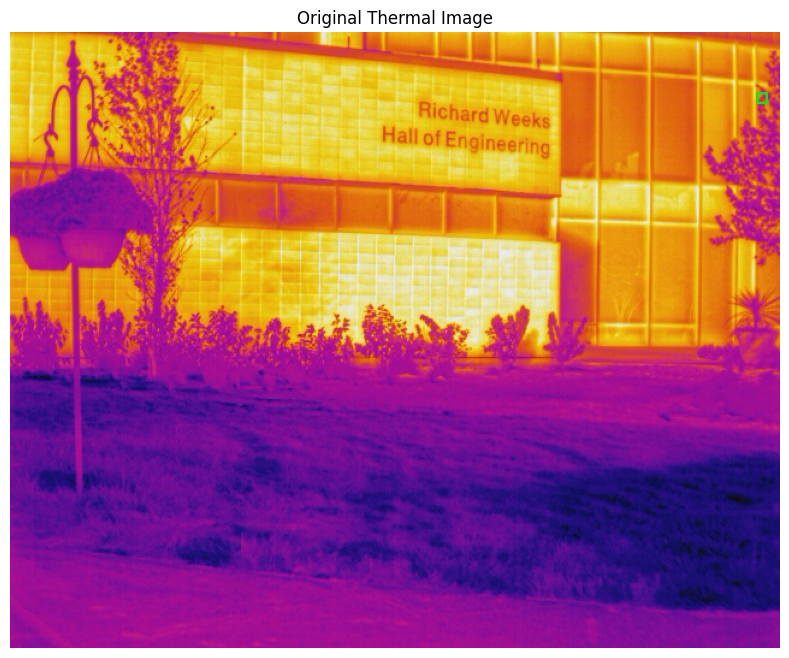

In [6]:
print("📤 Upload your thermal image:")
uploaded = files.upload()
IMAGE_PATH = list(uploaded.keys())[0]

# Load image
image = cv2.imread(IMAGE_PATH)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
h, w = gray.shape

print(f"\n📐 Image: {w}x{h}")
plt.figure(figsize=(12, 8))
plt.imshow(image_rgb)
plt.title('Original Thermal Image')
plt.axis('off')
plt.show()

## 3. Analyze Thermal Colormap
Thermal images use color to represent temperature. We'll use this to segment.

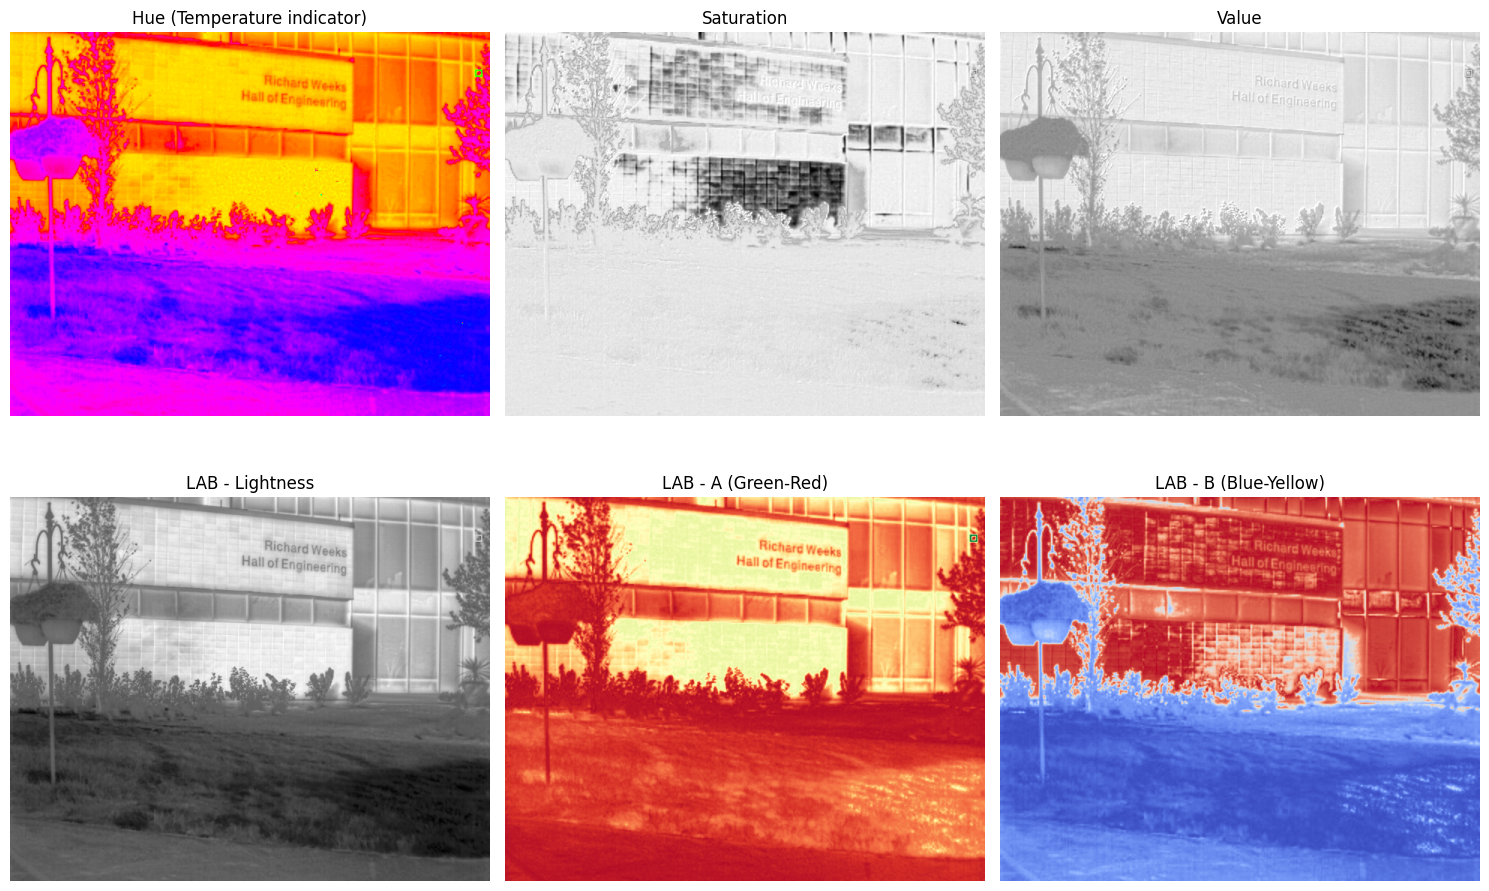

In [7]:
# Convert to different color spaces for analysis
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)

# Extract channels
h_channel = hsv[:,:,0]  # Hue - represents "color" in thermal palette
s_channel = hsv[:,:,1]  # Saturation
v_channel = hsv[:,:,2]  # Value/brightness

l_channel = lab[:,:,0]  # Lightness
a_channel = lab[:,:,1]  # Green-Red
b_channel = lab[:,:,2]  # Blue-Yellow

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes[0,0].imshow(h_channel, cmap='hsv')
axes[0,0].set_title('Hue (Temperature indicator)')
axes[0,1].imshow(s_channel, cmap='gray')
axes[0,1].set_title('Saturation')
axes[0,2].imshow(v_channel, cmap='gray')
axes[0,2].set_title('Value')
axes[1,0].imshow(l_channel, cmap='gray')
axes[1,0].set_title('LAB - Lightness')
axes[1,1].imshow(a_channel, cmap='RdYlGn_r')
axes[1,1].set_title('LAB - A (Green-Red)')
axes[1,2].imshow(b_channel, cmap='coolwarm')
axes[1,2].set_title('LAB - B (Blue-Yellow)')
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Improved Window Detection
Windows in thermal images typically:
- Have distinct color (often purple/blue = cooler, or bright = warmer)
- Are rectangular
- Have regular spacing patterns

In [8]:
def detect_windows_improved(image_rgb, hsv, gray):
    """
    Multi-method window detection for thermal images.
    """
    h, w = gray.shape
    window_mask = np.zeros((h, w), dtype=np.uint8)
    all_windows = []

    # === METHOD 1: Color-based detection ===
    # Windows often appear as purple/magenta (cooler) in iron palette
    # or as distinct yellow/bright spots (warmer interior)

    # Purple/Magenta range (cooler windows)
    lower_purple = np.array([120, 30, 30])
    upper_purple = np.array([170, 255, 255])
    purple_mask = cv2.inRange(hsv, lower_purple, upper_purple)

    # Yellow/Orange range (warmer windows showing interior heat)
    lower_yellow = np.array([15, 100, 150])
    upper_yellow = np.array([35, 255, 255])
    yellow_mask = cv2.inRange(hsv, lower_yellow, upper_yellow)

    # Bright spots (high intensity)
    _, bright_mask = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY)

    # === METHOD 2: Edge-based detection ===
    # Windows have strong rectangular edges
    edges = cv2.Canny(gray, 50, 150)

    # Dilate edges to connect nearby ones
    kernel_edge = np.ones((3,3), np.uint8)
    edges_dilated = cv2.dilate(edges, kernel_edge, iterations=1)

    # === METHOD 3: Local contrast ===
    # Windows have different temperature than surrounding wall
    blur = cv2.GaussianBlur(gray, (21, 21), 0)
    local_diff = cv2.absdiff(gray, blur)
    _, contrast_mask = cv2.threshold(local_diff, 15, 255, cv2.THRESH_BINARY)

    # === Combine methods ===
    combined = np.zeros_like(gray)
    combined = cv2.bitwise_or(combined, purple_mask)
    combined = cv2.bitwise_or(combined, yellow_mask)
    combined = cv2.bitwise_or(combined, bright_mask)
    combined = cv2.bitwise_and(combined, contrast_mask)  # Must have local contrast

    # Clean up with morphology
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
    combined = cv2.morphologyEx(combined, cv2.MORPH_CLOSE, kernel, iterations=2)
    combined = cv2.morphologyEx(combined, cv2.MORPH_OPEN, kernel, iterations=1)

    # Find contours
    contours, _ = cv2.findContours(combined, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Filter by shape and size
    min_area = (h * w) * 0.0005  # At least 0.05% of image
    max_area = (h * w) * 0.05    # At most 5% of image

    for cnt in contours:
        area = cv2.contourArea(cnt)
        if min_area < area < max_area:
            x, y, bw, bh = cv2.boundingRect(cnt)
            aspect = bw / max(bh, 1)

            # Windows are roughly rectangular (aspect 0.3 to 4)
            if 0.25 < aspect < 4.0:
                # Check rectangularity
                rect_area = bw * bh
                extent = area / rect_area if rect_area > 0 else 0

                if extent > 0.3:  # Reasonably rectangular
                    all_windows.append({
                        'contour': cnt,
                        'bbox': (x, y, bw, bh),
                        'area': area,
                        'aspect': aspect
                    })
                    cv2.drawContours(window_mask, [cnt], -1, 255, -1)

    debug_images = {
        'purple': purple_mask,
        'yellow': yellow_mask,
        'bright': bright_mask,
        'contrast': contrast_mask,
        'combined': combined
    }

    return all_windows, window_mask, debug_images

windows, window_mask, debug = detect_windows_improved(image_rgb, hsv, gray)
print(f"🪟 Detected {len(windows)} windows")

🪟 Detected 4 windows


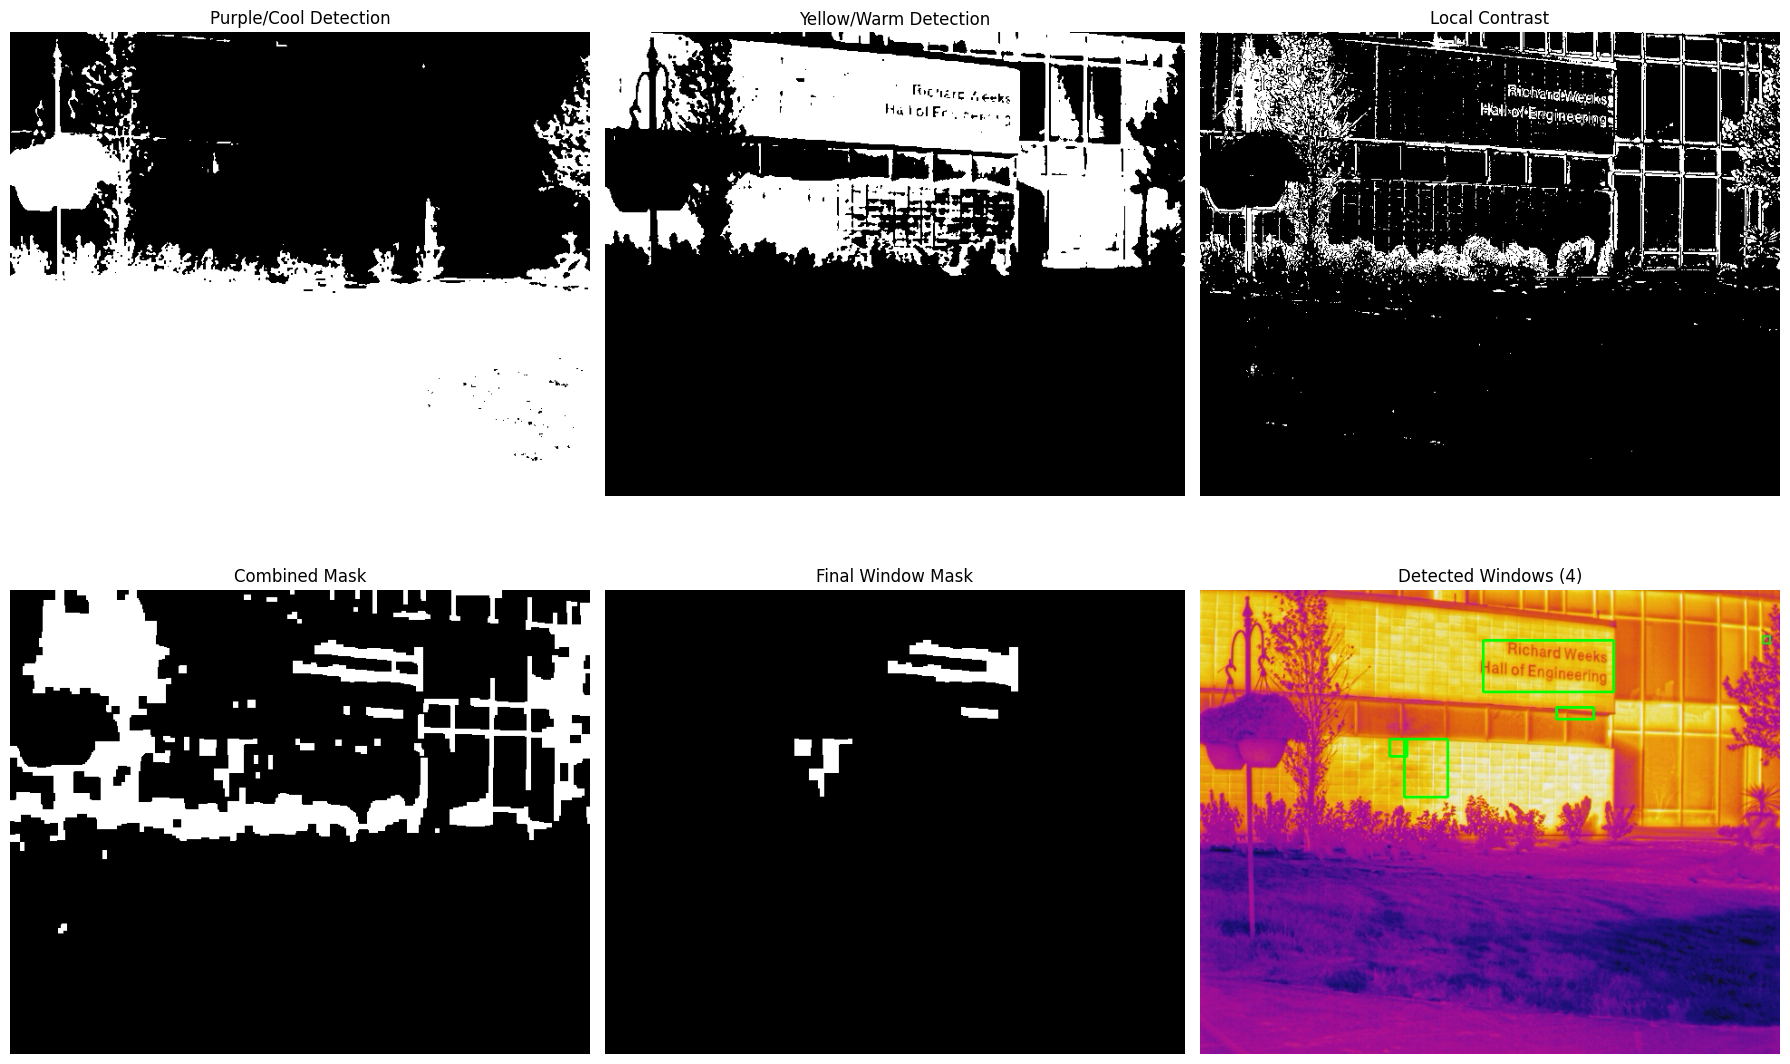

In [9]:
# Visualize detection steps
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

axes[0,0].imshow(debug['purple'], cmap='gray')
axes[0,0].set_title('Purple/Cool Detection')

axes[0,1].imshow(debug['yellow'], cmap='gray')
axes[0,1].set_title('Yellow/Warm Detection')

axes[0,2].imshow(debug['contrast'], cmap='gray')
axes[0,2].set_title('Local Contrast')

axes[1,0].imshow(debug['combined'], cmap='gray')
axes[1,0].set_title('Combined Mask')

axes[1,1].imshow(window_mask, cmap='gray')
axes[1,1].set_title('Final Window Mask')

# Draw detections on original
result = image_rgb.copy()
for win in windows:
    x, y, bw, bh = win['bbox']
    cv2.rectangle(result, (x, y), (x+bw, y+bh), (0, 255, 0), 2)
axes[1,2].imshow(result)
axes[1,2].set_title(f'Detected Windows ({len(windows)})')

for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Adjust Detection Parameters
Run this cell to fine-tune window detection for your specific image.

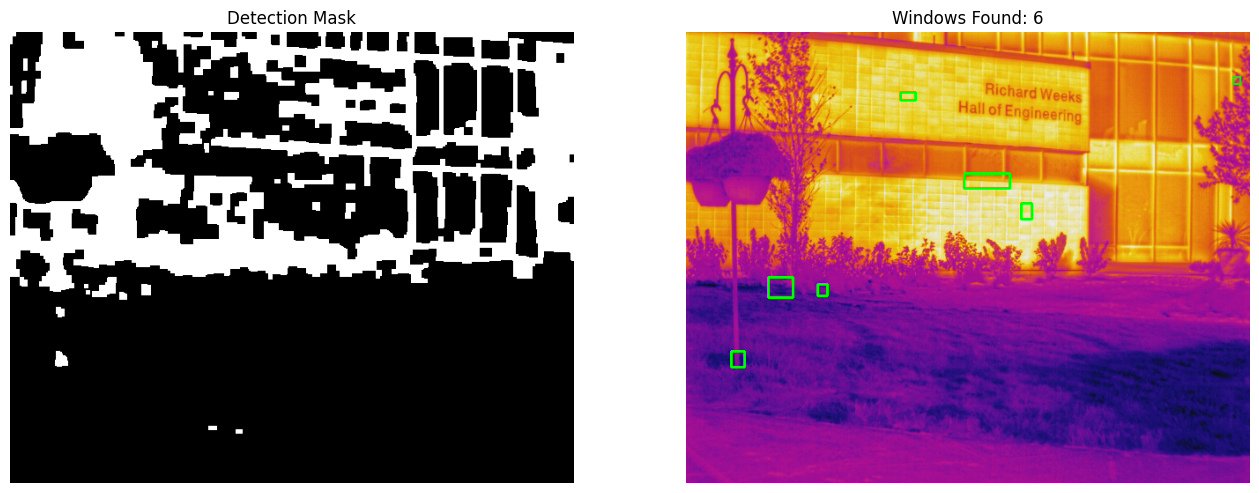

In [10]:
#@title Window Detection Parameters { run: "auto" }
#@markdown Adjust these sliders to improve detection:

purple_h_low = 100  #@param {type:"slider", min:0, max:180, step:5}
purple_h_high = 170  #@param {type:"slider", min:0, max:180, step:5}
purple_s_low = 20  #@param {type:"slider", min:0, max:255, step:10}
yellow_h_low = 10  #@param {type:"slider", min:0, max:60, step:5}
yellow_h_high = 40  #@param {type:"slider", min:0, max:60, step:5}
min_area_pct = 0.0003  #@param {type:"slider", min:0.0001, max:0.01, step:0.0001}
max_area_pct = 0.08  #@param {type:"slider", min:0.01, max:0.2, step:0.01}
min_rectangularity = 0.25  #@param {type:"slider", min:0.1, max:0.8, step:0.05}

def detect_windows_tunable(image_rgb, hsv, gray, params):
    h, w = gray.shape
    window_mask = np.zeros((h, w), dtype=np.uint8)
    all_windows = []

    # Purple range
    lower_purple = np.array([params['purple_h_low'], params['purple_s_low'], 30])
    upper_purple = np.array([params['purple_h_high'], 255, 255])
    purple_mask = cv2.inRange(hsv, lower_purple, upper_purple)

    # Yellow range
    lower_yellow = np.array([params['yellow_h_low'], 80, 120])
    upper_yellow = np.array([params['yellow_h_high'], 255, 255])
    yellow_mask = cv2.inRange(hsv, lower_yellow, upper_yellow)

    # Local contrast
    blur = cv2.GaussianBlur(gray, (21, 21), 0)
    local_diff = cv2.absdiff(gray, blur)
    _, contrast_mask = cv2.threshold(local_diff, 12, 255, cv2.THRESH_BINARY)

    # Combine
    combined = cv2.bitwise_or(purple_mask, yellow_mask)
    combined = cv2.bitwise_and(combined, contrast_mask)

    # Clean
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
    combined = cv2.morphologyEx(combined, cv2.MORPH_CLOSE, kernel, iterations=2)
    combined = cv2.morphologyEx(combined, cv2.MORPH_OPEN, kernel, iterations=1)

    # Find contours
    contours, _ = cv2.findContours(combined, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    min_area = (h * w) * params['min_area_pct']
    max_area = (h * w) * params['max_area_pct']

    for cnt in contours:
        area = cv2.contourArea(cnt)
        if min_area < area < max_area:
            x, y, bw, bh = cv2.boundingRect(cnt)
            aspect = bw / max(bh, 1)

            if 0.2 < aspect < 5.0:
                rect_area = bw * bh
                extent = area / rect_area if rect_area > 0 else 0

                if extent > params['min_rect']:
                    all_windows.append({'contour': cnt, 'bbox': (x, y, bw, bh), 'area': area})
                    cv2.drawContours(window_mask, [cnt], -1, 255, -1)

    return all_windows, window_mask, combined

params = {
    'purple_h_low': purple_h_low,
    'purple_h_high': purple_h_high,
    'purple_s_low': purple_s_low,
    'yellow_h_low': yellow_h_low,
    'yellow_h_high': yellow_h_high,
    'min_area_pct': min_area_pct,
    'max_area_pct': max_area_pct,
    'min_rect': min_rectangularity
}

windows_tuned, window_mask_tuned, combined_tuned = detect_windows_tunable(image_rgb, hsv, gray, params)

# Show result
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(combined_tuned, cmap='gray')
axes[0].set_title('Detection Mask')
axes[0].axis('off')

result = image_rgb.copy()
for win in windows_tuned:
    x, y, bw, bh = win['bbox']
    cv2.rectangle(result, (x, y), (x+bw, y+bh), (0, 255, 0), 2)
axes[1].imshow(result)
axes[1].set_title(f'Windows Found: {len(windows_tuned)}')
axes[1].axis('off')
plt.show()

# Update global mask
window_mask = window_mask_tuned
windows = windows_tuned

## 6. Wall Detection
Walls are the large, relatively uniform temperature regions between windows.

In [11]:
def detect_walls(image_rgb, hsv, gray, window_mask):
    """
    Detect wall regions - typically warm/orange areas in thermal images.
    Walls are everything that's NOT a window and has consistent temperature.
    """
    h, w = gray.shape

    # === Method 1: Color-based wall detection ===
    # Walls in iron palette are typically orange/red (warm)

    # Orange-red range (typical wall temperature)
    lower_orange = np.array([5, 50, 100])
    upper_orange = np.array([25, 255, 255])
    orange_mask = cv2.inRange(hsv, lower_orange, upper_orange)

    # Red range
    lower_red1 = np.array([0, 50, 100])
    upper_red1 = np.array([10, 255, 255])
    red_mask1 = cv2.inRange(hsv, lower_red1, upper_red1)

    lower_red2 = np.array([170, 50, 100])
    upper_red2 = np.array([180, 255, 255])
    red_mask2 = cv2.inRange(hsv, lower_red2, upper_red2)

    # Combine warm colors
    wall_color_mask = cv2.bitwise_or(orange_mask, red_mask1)
    wall_color_mask = cv2.bitwise_or(wall_color_mask, red_mask2)

    # === Method 2: Remove non-wall regions ===
    # Exclude windows
    wall_mask = wall_color_mask.copy()
    wall_mask[window_mask > 0] = 0

    # === Method 3: Clean up with morphology ===
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7))
    wall_mask = cv2.morphologyEx(wall_mask, cv2.MORPH_CLOSE, kernel, iterations=3)
    wall_mask = cv2.morphologyEx(wall_mask, cv2.MORPH_OPEN, kernel, iterations=2)

    # Fill holes
    wall_mask = ndimage.binary_fill_holes(wall_mask).astype(np.uint8) * 255

    # Remove windows again (they might have been filled)
    wall_mask[window_mask > 0] = 0

    return wall_mask, wall_color_mask

wall_mask, wall_color = detect_walls(image_rgb, hsv, gray, window_mask)
print(f"🧱 Wall coverage: {np.sum(wall_mask > 0) / wall_mask.size * 100:.1f}%")

🧱 Wall coverage: 50.4%


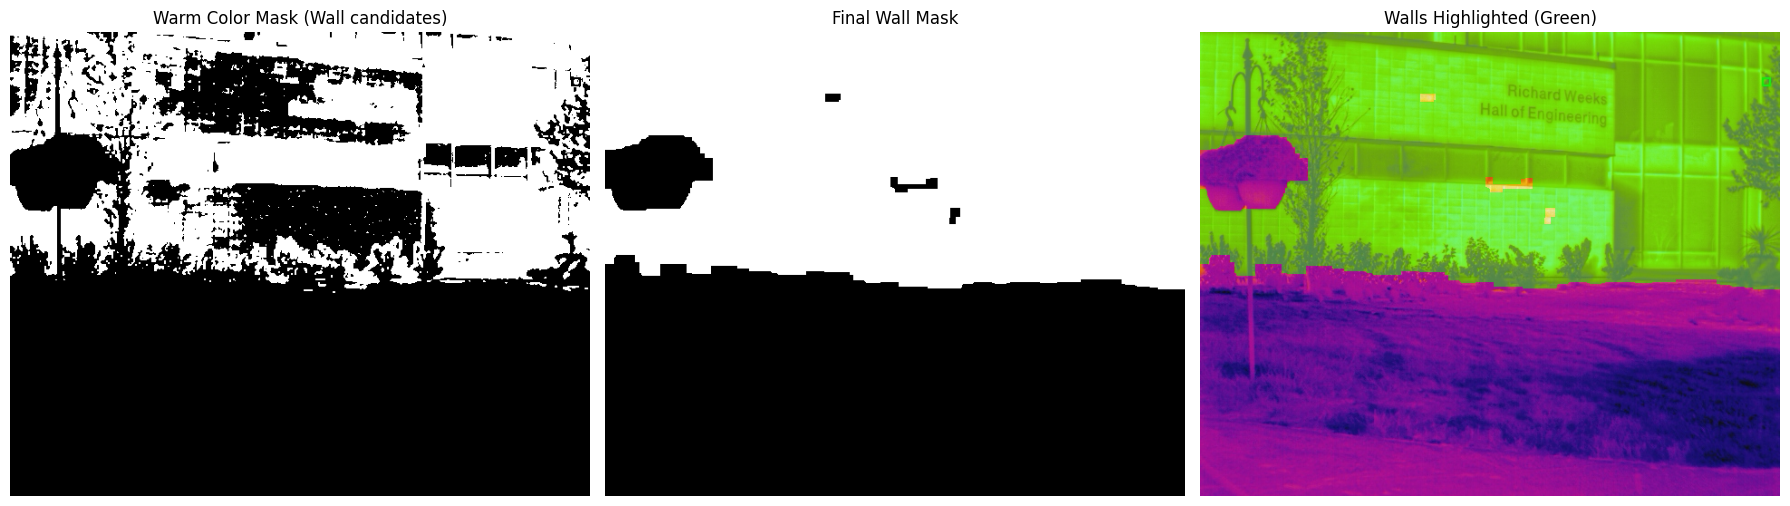

In [12]:
# Visualize wall detection
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(wall_color, cmap='gray')
axes[0].set_title('Warm Color Mask (Wall candidates)')
axes[0].axis('off')

axes[1].imshow(wall_mask, cmap='gray')
axes[1].set_title('Final Wall Mask')
axes[1].axis('off')

# Overlay on image
overlay = image_rgb.copy().astype(float) / 255
overlay[wall_mask > 0] = overlay[wall_mask > 0] * 0.5 + np.array([0, 1, 0]) * 0.5
axes[2].imshow(overlay)
axes[2].set_title('Walls Highlighted (Green)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

## 7. Roof Detection
Roof is typically at the top of the image with different thermal signature.

In [13]:
def detect_roof(image_rgb, hsv, gray, wall_mask, window_mask):
    """
    Detect roof regions - often cooler (purple/blue) or different texture.
    Located primarily in upper portion of image.
    """
    h, w = gray.shape

    # Start with upper region of image
    upper_region = np.zeros((h, w), dtype=np.uint8)
    upper_region[:int(h * 0.5), :] = 255  # Top 50%

    # === Method 1: Color-based - cooler regions ===
    # Purple/Blue (cooler temperatures)
    lower_cool = np.array([100, 30, 30])
    upper_cool = np.array([150, 255, 255])
    cool_mask = cv2.inRange(hsv, lower_cool, upper_cool)

    # Pink/Magenta (transition temperatures)
    lower_pink = np.array([150, 30, 100])
    upper_pink = np.array([175, 255, 255])
    pink_mask = cv2.inRange(hsv, lower_pink, upper_pink)

    # Combine cool colors
    roof_color = cv2.bitwise_or(cool_mask, pink_mask)

    # === Method 2: Texture-based ===
    # Roofs often have different texture (gravel, tiles)
    # Use local variance
    kernel_size = 11
    local_mean = cv2.blur(gray.astype(float), (kernel_size, kernel_size))
    local_sqmean = cv2.blur(gray.astype(float)**2, (kernel_size, kernel_size))
    local_var = local_sqmean - local_mean**2
    local_var = np.clip(local_var, 0, None)

    # High variance areas might be textured roof
    var_thresh = np.percentile(local_var, 70)
    texture_mask = (local_var > var_thresh).astype(np.uint8) * 255

    # === Combine methods ===
    roof_mask = cv2.bitwise_or(roof_color, texture_mask)

    # Apply upper region constraint
    roof_mask = cv2.bitwise_and(roof_mask, upper_region)

    # Remove walls and windows
    roof_mask[wall_mask > 0] = 0
    roof_mask[window_mask > 0] = 0

    # Clean up
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    roof_mask = cv2.morphologyEx(roof_mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    roof_mask = cv2.morphologyEx(roof_mask, cv2.MORPH_OPEN, kernel, iterations=1)

    return roof_mask, roof_color

roof_mask, roof_color = detect_roof(image_rgb, hsv, gray, wall_mask, window_mask)
print(f"🏠 Roof coverage: {np.sum(roof_mask > 0) / roof_mask.size * 100:.1f}%")

🏠 Roof coverage: 2.4%


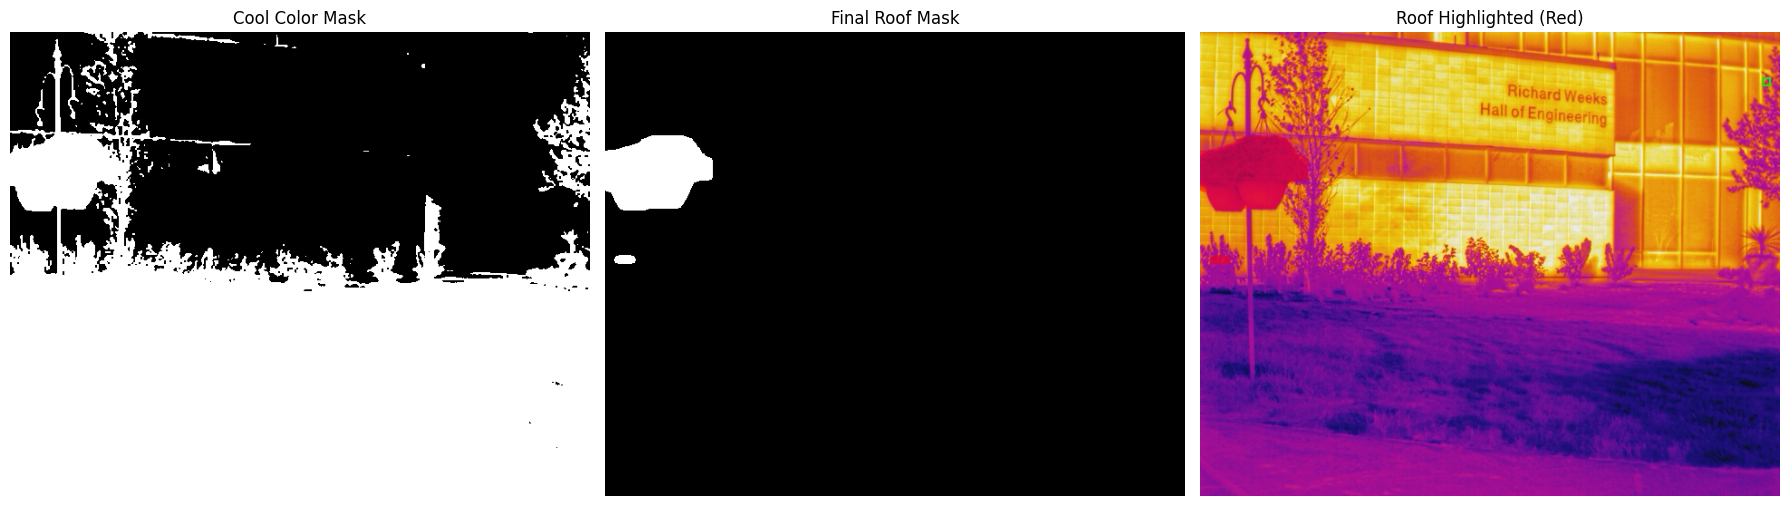

In [14]:
# Visualize roof detection
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(roof_color, cmap='gray')
axes[0].set_title('Cool Color Mask')
axes[0].axis('off')

axes[1].imshow(roof_mask, cmap='gray')
axes[1].set_title('Final Roof Mask')
axes[1].axis('off')

overlay = image_rgb.copy().astype(float) / 255
overlay[roof_mask > 0] = overlay[roof_mask > 0] * 0.5 + np.array([1, 0, 0]) * 0.5
axes[2].imshow(overlay)
axes[2].set_title('Roof Highlighted (Red)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

## 8. Final Combined Segmentation

In [15]:
# Store all masks
component_masks = {
    'roof': roof_mask,
    'wall': wall_mask,
    'window': window_mask
}

# Print statistics
print("="*50)
print("📊 SEGMENTATION RESULTS")
print("="*50)
total_segmented = 0
for name, mask in component_masks.items():
    pixels = np.sum(mask > 0)
    pct = pixels / mask.size * 100
    total_segmented += pixels
    print(f"{name.upper():8s}: {pixels:>8,} pixels ({pct:5.1f}%)")

unsegmented = mask.size - total_segmented
print(f"{'OTHER':8s}: {unsegmented:>8,} pixels ({unsegmented/mask.size*100:5.1f}%)")

📊 SEGMENTATION RESULTS
ROOF    :    7,901 pixels (  2.4%)
WALL    :  165,103 pixels ( 50.4%)
WINDOW  :    1,507 pixels (  0.5%)
OTHER   :  153,169 pixels ( 46.7%)


In [ ]:
# Create beautiful combined visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# Original
axes[0, 0].imshow(image_rgb)
axes[0, 0].set_title('Original Thermal Image', fontsize=14)
axes[0, 0].axis('off')

# Individual masks side by side
mask_combined = np.zeros((h, w, 3), dtype=np.uint8)
mask_combined[roof_mask > 0] = [255, 0, 0]      # Red for roof
mask_combined[wall_mask > 0] = [0, 255, 0]      # Green for walls
mask_combined[window_mask > 0] = [0, 0, 255]    # Blue for windows

axes[0, 1].imshow(mask_combined)
axes[0, 1].set_title('Segmentation Masks', fontsize=14)
axes[0, 1].axis('off')

# Windows with bounding boxes
result_windows = image_rgb.copy()
for win in windows:
    x, y, bw, bh = win['bbox']
    cv2.rectangle(result_windows, (x, y), (x+bw, y+bh), (0, 255, 0), 2)
axes[1, 0].imshow(result_windows)
axes[1, 0].set_title(f'Detected Windows ({len(windows)})', fontsize=14)
axes[1, 0].axis('off')

# Combined overlay
overlay = image_rgb.copy().astype(float) / 255
alpha = 0.4

# Apply colored overlays
overlay[roof_mask > 0] = overlay[roof_mask > 0] * (1-alpha) + np.array([1, 0, 0]) * alpha
overlay[wall_mask > 0] = overlay[wall_mask > 0] * (1-alpha) + np.array([0, 1, 0]) * alpha
overlay[window_mask > 0] = overlay[window_mask > 0] * (1-alpha) + np.array([0, 0, 1]) * alpha

axes[1, 1].imshow(np.clip(overlay, 0, 1))
axes[1, 1].set_title('Combined Overlay', fontsize=14)
axes[1, 1].axis('off')

# Add legend
from matplotlib.patches import Patch
legend = [
    Patch(facecolor='red', alpha=0.6, label='Roof'),
    Patch(facecolor='green', alpha=0.6, label='Wall'),
    Patch(facecolor='blue', alpha=0.6, label='Window')
]
axes[1, 1].legend(handles=legend, loc='upper right', fontsize=12)

plt.tight_layout()
plt.savefig('segmentation_result.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n💾 Saved as 'segmentation_result.png'")

## 9. Thermal Statistics per Component

In [ ]:
# Calculate thermal stats for each component
print("\n" + "="*60)
print("🌡️  THERMAL STATISTICS BY COMPONENT")
print("="*60)

thermal_stats = {}
for name, mask in component_masks.items():
    if np.sum(mask > 0) > 0:
        values = gray[mask > 0]
        thermal_stats[name] = {
            'mean': np.mean(values),
            'std': np.std(values),
            'min': np.min(values),
            'max': np.max(values),
            'median': np.median(values),
            'count': len(values)
        }

        print(f"\n{name.upper()}:")
        print(f"  Mean:   {thermal_stats[name]['mean']:.1f}")
        print(f"  Std:    {thermal_stats[name]['std']:.1f}")
        print(f"  Range:  {thermal_stats[name]['min']} - {thermal_stats[name]['max']}")
        print(f"  Median: {thermal_stats[name]['median']:.1f}")

In [ ]:
# Histogram comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
colors = {'roof': 'red', 'wall': 'green', 'window': 'blue'}

for i, (name, color) in enumerate(colors.items()):
    mask = component_masks[name]
    if np.sum(mask > 0) > 0:
        values = gray[mask > 0]
        axes[i].hist(values, bins=50, color=color, alpha=0.7, edgecolor='black')
        axes[i].axvline(np.mean(values), color='black', linestyle='--',
                       label=f'Mean: {np.mean(values):.1f}')
        axes[i].set_title(f'{name.capitalize()} Temperature Distribution')
        axes[i].set_xlabel('Intensity (proxy for temperature)')
        axes[i].set_ylabel('Pixel count')
        axes[i].legend()
    else:
        axes[i].set_title(f'{name.capitalize()} - No data')

plt.tight_layout()
plt.show()

## 10. Export Results

In [ ]:
import os

output_dir = 'segmentation_output'
os.makedirs(output_dir, exist_ok=True)

# Save individual masks
for name, mask in component_masks.items():
    cv2.imwrite(f'{output_dir}/{name}_mask.png', mask)

    # Save extracted region
    region = image_rgb.copy()
    region[mask == 0] = 0
    cv2.imwrite(f'{output_dir}/{name}_region.png', cv2.cvtColor(region, cv2.COLOR_RGB2BGR))

# Save combined labels (1=roof, 2=wall, 3=window)
labels = np.zeros(gray.shape, dtype=np.uint8)
labels[roof_mask > 0] = 1
labels[wall_mask > 0] = 2
labels[window_mask > 0] = 3
cv2.imwrite(f'{output_dir}/labels.png', labels)

# Save numpy archive for easy loading
np.savez(f'{output_dir}/segmentation_data.npz',
         image=image_rgb,
         gray=gray,
         labels=labels,
         roof_mask=roof_mask,
         wall_mask=wall_mask,
         window_mask=window_mask)

# Save visualization
cv2.imwrite(f'{output_dir}/result_overlay.png',
            cv2.cvtColor((np.clip(overlay, 0, 1) * 255).astype(np.uint8), cv2.COLOR_RGB2BGR))

print(f"✅ Results saved to '{output_dir}/'")
print("\nFiles created:")
for f in sorted(os.listdir(output_dir)):
    size = os.path.getsize(f'{output_dir}/{f}') / 1024
    print(f"  {f}: {size:.1f} KB")

In [ ]:
# Download as zip
!zip -r segmentation_output.zip segmentation_output/
files.download('segmentation_output.zip')
print("\n📥 Download started!")

## 11. Quick Load for Anomaly Detection

Use this code to load your segmentation results:

In [ ]:
# Example: Load saved data
data = np.load('segmentation_output/segmentation_data.npz')

print("Available arrays:")
for key in data.files:
    arr = data[key]
    print(f"  {key}: shape={arr.shape}, dtype={arr.dtype}")

# Quick access
roof = data['roof_mask']
wall = data['wall_mask']
window = data['window_mask']
original = data['image']
gray_img = data['gray']

print("\n✅ Ready for anomaly detection!")
print("\nNext steps:")
print("  - Analyze temperature distribution within each component")
print("  - Look for hot/cold spots that deviate from the mean")
print("  - Compare adjacent regions for thermal bridges")

---
## Summary

**Improvements in this version:**

1. **Color-space analysis** - Uses HSV to detect thermal colormap colors
2. **Multi-method detection** - Combines color, contrast, and shape analysis
3. **Tunable parameters** - Interactive sliders to adjust detection
4. **Better window detection** - Looks for purple/blue (cool) and bright yellow (warm) regions
5. **Wall detection** - Identifies warm orange/red regions
6. **Roof detection** - Finds cooler upper regions with different texture

**For your anomaly detection:**
- Window thermal stats show interior heat leakage
- Wall uniformity indicates insulation quality
- Roof temperature differences reveal heat loss areas